<a href="https://colab.research.google.com/github/madwikpoojari-a11y/Unemployment__Analysis/blob/main/Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9



Column names:
['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Missing values:
Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64
Cleaned dataset:


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


Dataset shape: (200, 5)
Mean Absolute Error: 1.4650601050102927
Root Mean Squared Error: 1.788576100865966
R2 Score: 0.8986489151417081


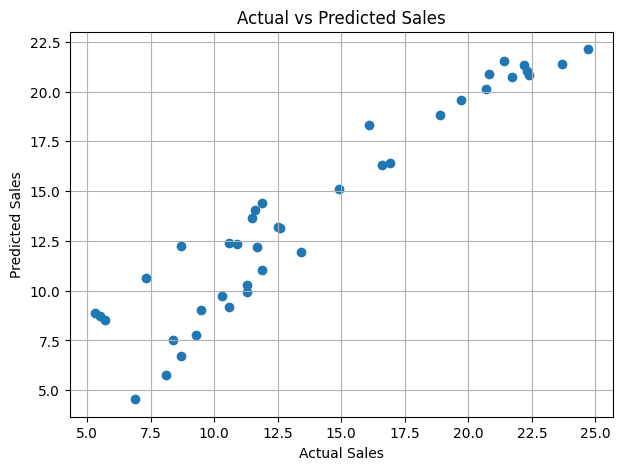

Correlation with Sales:
TV            0.782224
Radio         0.576223
Newspaper     0.228299
Unnamed: 0   -0.051616
Name: Sales, dtype: float64


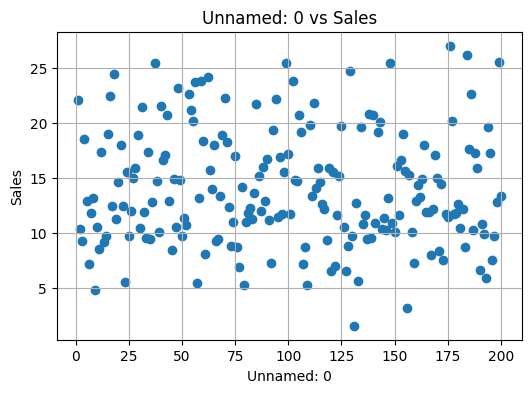

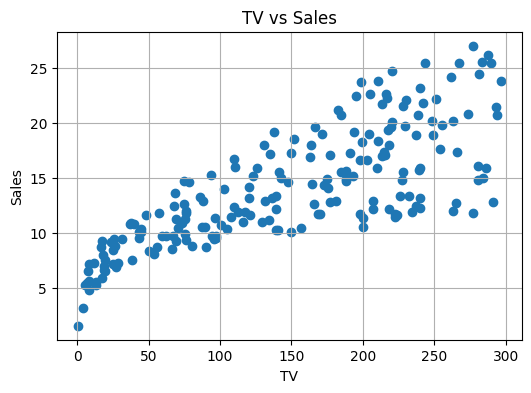

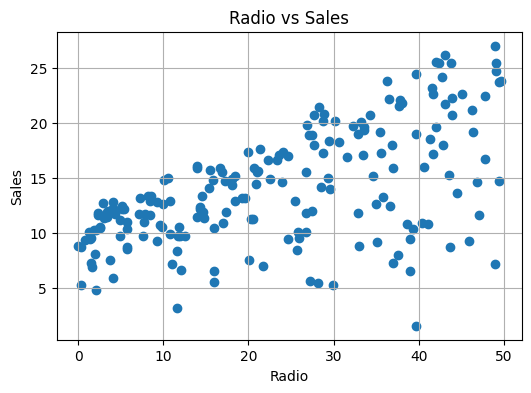

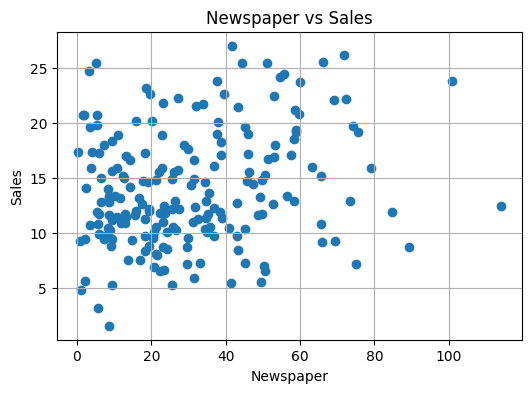

Campaign details:


,Unnamed: 0,TV,Radio,Newspaper
95,96,163.3,31.6,52.9


Predicted sales: 16.41


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Upload the CSV file
from IPython.display import display
import os

# Read the CSV file directly
df = pd.read_csv("Advertising1.csv")

print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())
# Remove duplicate rows
df = df.drop_duplicates()

# Remove spaces from column names
df.columns = df.columns.str.strip()

# Find the sales column
sales_col = next(
    (c for c in df.columns if c.lower().strip() == "sales"),
    None
)

if sales_col is None:
    raise ValueError(
        "Sales column not found. Check your column names."
    )

# Convert sales to numeric values
df[sales_col] = pd.to_numeric(
    df[sales_col], errors="coerce"
)

# Remove rows where sales is missing
df = df.dropna(subset=[sales_col])

# Fill missing numerical values with their median
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

# Fill missing categorical values with the most frequent value
categorical_cols = df.select_dtypes(
    exclude="number"
).columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode().iloc[0])

print("Cleaned dataset:")
display(df.head())
print("Dataset shape:", df.shape)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select input features and sales target
X = df.drop(columns=[sales_col])
y = df[sales_col]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

# Prepare numerical and categorical data
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer([
    ("num", make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    ), num_cols),
    ("cat", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), cat_cols)
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Build and train the model
model = make_pipeline(
    preprocessor,
    LinearRegression()
)

model.fit(X_train, y_train)

# Predict sales
predictions = model.predict(X_test)

# Evaluate the model
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.grid(True)
plt.show()
# Correlation between numerical columns and sales
correlation = df.select_dtypes(include="number").corr()[sales_col]
correlation = correlation.drop(sales_col, errors="ignore")

print("Correlation with Sales:")
print(correlation.sort_values(ascending=False))

# Plot numerical features against sales
for col in correlation.index:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df[sales_col])
    plt.xlabel(col)
    plt.ylabel("Sales")
    plt.title(f"{col} vs Sales")
    plt.grid(True)
    plt.show()
    # Take one campaign from the test data
new_campaign = X_test.iloc[[0]]

# Predict its sales
future_sales = model.predict(new_campaign)

print("Campaign details:")
display(new_campaign)

print("Predicted sales:", round(float(future_sales[0]), 2))